<a href="https://colab.research.google.com/github/manisha17marndi-lgtm/ecommerce-funnel-retention-analytics./blob/main/notebooks/funnel_retention_validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
from google.colab import auth
auth.authenticate_user()

from google.cloud import bigquery
import pandas as pd

client = bigquery.Client(project='ga4-funnel-project-515805')

users = client.query("""
    SELECT * FROM `ga4-funnel-project-515805.ga4_project.rpt_user_metrics`
""").to_dataframe()

print(users.shape)
users.head()

(257299, 19)


,user_id,first_visit_date,cohort_week,channel_group,device_category,eligible_d1,eligible_d7_and_funnel,eligible_d30_and_repeat,did_view_item_7d,did_add_to_cart_7d,did_begin_checkout_7d,orders_7d,revenue_7d,orders_30d,ret_d1_session,ret_d7_session,ret_d30_session,ret_d1_shopping,ret_d7_shopping
0,79772400.2663581547,2020-11-01,2020-11-01,Data deleted / other,desktop,True,True,True,True,False,True,0,0.0,0,False,False,False,False,False
1,3969608.9768981542,2020-11-03,2020-11-01,Data deleted / other,mobile,True,True,True,False,False,False,0,0.0,0,True,False,False,False,False
2,18134304.4702227145,2020-11-03,2020-11-01,Data deleted / other,desktop,True,True,True,False,False,False,0,0.0,0,False,False,False,False,False
3,28501628.5968300908,2020-11-03,2020-11-01,Data deleted / other,desktop,True,True,True,False,False,False,0,0.0,0,False,False,False,False,False
4,72247217.2012519479,2020-11-04,2020-11-01,Data deleted / other,desktop,True,True,True,False,False,False,0,0.0,0,False,False,False,False,False


In [8]:
print("shape:", users.shape)
print("distinct users:", users['user_id'].nunique())

f = users[users['eligible_d7_and_funnel']]
print("funnel cohort:", len(f))
print("viewed item:", int(f['did_view_item_7d'].sum()))
print("added to cart:", int(f['did_add_to_cart_7d'].sum()))
print("began checkout:", int(f['did_begin_checkout_7d'].sum()))
print("buyers (7d):", int((f['orders_7d'] > 0).sum()))
print("revenue (7d):", round(f['revenue_7d'].sum(), 2))

print("D1 returned:", int(users.loc[users['eligible_d1'], 'ret_d1_session'].sum()))
print("D7 returned:", int(f['ret_d7_session'].sum()))
print("D30 returned:", int(users.loc[users['eligible_d30_and_repeat'], 'ret_d30_session'].sum()))

shape: (257299, 19)
distinct users: 257299
funnel cohort: 238636
viewed item: 50110
added to cart: 9644
began checkout: 7231
buyers (7d): 2424
revenue (7d): 185106.0
D1 returned: 10754
D7 returned: 1586
D30 returned: 223


In [9]:
from datetime import date

raw = client.query("""
    SELECT user_pseudo_id AS user_id,
           TIMESTAMP_MICROS(event_timestamp) AS ts,
           ecommerce.transaction_id AS order_id,
           ecommerce.purchase_revenue_in_usd AS revenue
    FROM `bigquery-public-data.ga4_obfuscated_sample_ecommerce.events_*`
    WHERE _TABLE_SUFFIX BETWEEN '20201101' AND '20210131'
      AND event_name = 'purchase'
""").to_dataframe()

fv = client.query("""
    SELECT user_id, first_visit_ts, had_earlier_activity
    FROM `ga4-funnel-project-515805.ga4_project.users_with_channel`
""").to_dataframe()

print("raw purchase events (all users):", len(raw))

p = raw.merge(fv, on='user_id', how='inner')
print("purchase events for users in users table:", len(p))

valid = p[p['order_id'].notna() & (p['order_id'] != '(not set)') & (p['revenue'] > 0)]
orders_py = (valid.sort_values('ts')
                  .drop_duplicates(['order_id', 'user_id'], keep='first'))

print("valid orders:", len(orders_py))
print("buyers:", orders_py['user_id'].nunique())
print("revenue:", round(orders_py['revenue'].sum(), 2))

cut = pd.Timestamp('2021-01-24', tz='UTC')
o7 = orders_py[
    (~orders_py['had_earlier_activity'])
    & (orders_py['first_visit_ts'].dt.normalize() <= cut)
    & (orders_py['ts'] >= orders_py['first_visit_ts'])
    & (orders_py['ts'] <= orders_py['first_visit_ts'] + pd.Timedelta(days=7))
]
print("7-day orders:", len(o7))
print("7-day buyers:", o7['user_id'].nunique())
print("7-day revenue:", round(o7['revenue'].sum(), 2))

raw purchase events (all users): 5692
purchase events for users in users table: 4409
valid orders: 3542
buyers: 3007
revenue: 243430.0
7-day orders: 2739
7-day buyers: 2424
7-day revenue: 185106.0


In [10]:
import numpy as np
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from statsmodels.stats.multitest import multipletests

users['cohort_week'] = pd.to_datetime(users['cohort_week'])
users['bought_7d'] = users['orders_7d'] > 0
f = users[users['eligible_d7_and_funnel']].copy()

org = f[f['channel_group'] == 'Organic Search']
paid = f[f['channel_group'] == 'Paid Search']
store = f[f['channel_group'] == 'Store referral (own domain)']
desk = f[f['device_category'] == 'desktop']
mob = f[f['device_category'] == 'mobile']
tab = f[f['device_category'] == 'tablet']

d1 = users[users['eligible_d1']]
d7 = users[users['eligible_d7_and_funnel']]
early = lambda d: d[d['cohort_week'] <= '2020-11-29']
holi = lambda d: d[d['cohort_week'].isin(pd.to_datetime(['2020-12-13', '2020-12-20', '2020-12-27']))]

tests = [
    ("Checkout to purchase: Store referral vs Organic",
     store[store['did_begin_checkout_7d']]['bought_7d'], org[org['did_begin_checkout_7d']]['bought_7d']),
    ("View to cart: Paid Search vs Organic",
     paid[paid['did_view_item_7d']]['did_add_to_cart_7d'], org[org['did_view_item_7d']]['did_add_to_cart_7d']),
    ("Purchased in 7 days: Paid Search vs Organic", paid['bought_7d'], org['bought_7d']),
    ("Purchased in 7 days: Desktop vs Mobile", desk['bought_7d'], mob['bought_7d']),
    ("Purchased in 7 days: Tablet vs Desktop", tab['bought_7d'], desk['bought_7d']),
    ("Day 1 return: Nov cohorts vs mid/late-Dec cohorts",
     early(d1)['ret_d1_session'].astype(bool), holi(d1)['ret_d1_session'].astype(bool)),
    ("Day 7 return: Nov cohorts vs mid/late-Dec cohorts",
     early(d7)['ret_d7_session'].astype(bool), holi(d7)['ret_d7_session'].astype(bool)),
    ("Day 7 return: Store referral vs Organic",
     store['ret_d7_session'].astype(bool), org['ret_d7_session'].astype(bool)),
    ("Day 1 return: Paid Search vs Organic",
     d1[d1['channel_group'] == 'Paid Search']['ret_d1_session'].astype(bool),
     d1[d1['channel_group'] == 'Organic Search']['ret_d1_session'].astype(bool)),
]

rows = []
for name, a, b in tests:
    xa, na, xb, nb = int(a.sum()), len(a), int(b.sum()), len(b)
    z, p = proportions_ztest([xa, xb], [na, nb])
    la, ha = proportion_confint(xa, na, method='wilson')
    lb, hb = proportion_confint(xb, nb, method='wilson')
    rows.append({
        'test': name,
        'rate_a_%': round(100 * xa / na, 2), 'n_a': na,
        'ci_a_%': f"{100*la:.2f}-{100*ha:.2f}",
        'rate_b_%': round(100 * xb / nb, 2), 'n_b': nb,
        'ci_b_%': f"{100*lb:.2f}-{100*hb:.2f}",
        'diff_pp': round(100 * (xa / na - xb / nb), 2),
        'z': round(z, 2), 'p_raw': p
    })

res = pd.DataFrame(rows)
res['p_holm'] = multipletests(res['p_raw'], method='holm')[1]
res['p_raw'] = res['p_raw'].round(4)
res['p_holm'] = res['p_holm'].round(4)
pd.set_option('display.width', 250)
pd.set_option('display.max_colwidth', 60)
print(res.to_string(index=False))

ch = users[['user_id', 'channel_group']]
o7c = o7.merge(ch, on='user_id')
a = o7c.loc[o7c['channel_group'] == 'Paid Search', 'revenue'].values
b = o7c.loc[o7c['channel_group'] == 'Organic Search', 'revenue'].values
rng = np.random.default_rng(42)
diffs = np.array([rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(10000)])
print("\nPaid orders:", len(a), "Organic orders:", len(b))
print("Mean order value Paid:", round(a.mean(), 2), "Organic:", round(b.mean(), 2))
print("Bootstrap 95% CI for difference:", round(np.percentile(diffs, 2.5), 2), "to", round(np.percentile(diffs, 97.5), 2))

                                             test  rate_a_%    n_a      ci_a_%  rate_b_%    n_b      ci_b_%  diff_pp     z  p_raw  p_holm
  Checkout to purchase: Store referral vs Organic     28.35    381 24.05-33.07     34.04   2782 32.30-35.82    -5.69 -2.21 0.0271  0.1894
             View to cart: Paid Search vs Organic     17.63   2705 16.24-19.12     18.77  19279 18.23-19.33    -1.14 -1.42 0.1547  0.7009
      Purchased in 7 days: Paid Search vs Organic      1.02  13049   0.86-1.21      1.03  91545   0.97-1.10    -0.02 -0.16 0.8721  1.0000
           Purchased in 7 days: Desktop vs Mobile      1.01 138616   0.96-1.06      1.04  94670   0.97-1.10    -0.03 -0.73 0.4654  1.0000
           Purchased in 7 days: Tablet vs Desktop      0.88   5350   0.66-1.17      1.01 138616   0.96-1.06    -0.13 -0.92 0.3567  1.0000
Day 1 return: Nov cohorts vs mid/late-Dec cohorts      5.16  87461   5.02-5.31      3.32  58145   3.18-3.47     1.84 16.72 0.0000  0.0000
Day 7 return: Nov cohorts vs mid/l

In [11]:
d = users[users['eligible_d7_and_funnel']].copy()
d['returned_d1'] = d['ret_d1_session'].astype(bool)
d['bought_7d'] = d['orders_7d'] > 0

summary = d.groupby('returned_d1').agg(
    users=('user_id', 'count'),
    viewed_item=('did_view_item_7d', 'mean'),
    added_to_cart=('did_add_to_cart_7d', 'mean'),
    began_checkout=('did_begin_checkout_7d', 'mean'),
    bought=('bought_7d', 'mean'),
    avg_revenue_7d=('revenue_7d', 'mean')
).round(4)
print(summary)

print("\nChannel mix (share of each group):")
print(pd.crosstab(d['channel_group'], d['returned_d1'], normalize='columns').round(4))

print("\nDevice mix (share of each group):")
print(pd.crosstab(d['device_category'], d['returned_d1'], normalize='columns').round(4))

              users  viewed_item  added_to_cart  began_checkout  bought  avg_revenue_7d
returned_d1                                                                            
False        228532       0.1983         0.0357          0.0267   0.008          0.5634
True          10104       0.4747          0.147          0.1119  0.0586          5.5768

Channel mix (share of each group):
returned_d1                   False   True 
channel_group                              
Data deleted / other         0.0003  0.0008
Direct                       0.2381  0.2449
Organic Search               0.3838  0.3786
Paid Search                  0.0546  0.0570
Referral                     0.0932  0.0912
Store referral (own domain)  0.0495  0.0497
Unclassified (obfuscated)    0.1805  0.1779

Device mix (share of each group):
returned_d1       False   True 
device_category                
desktop          0.5810  0.5773
mobile           0.3966  0.3993
tablet           0.0224  0.0234


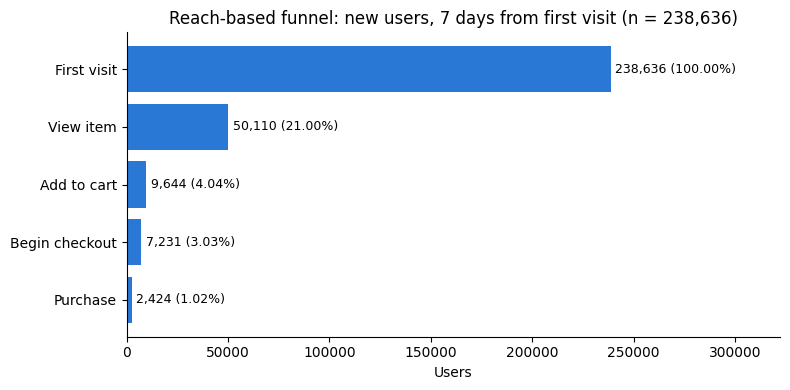

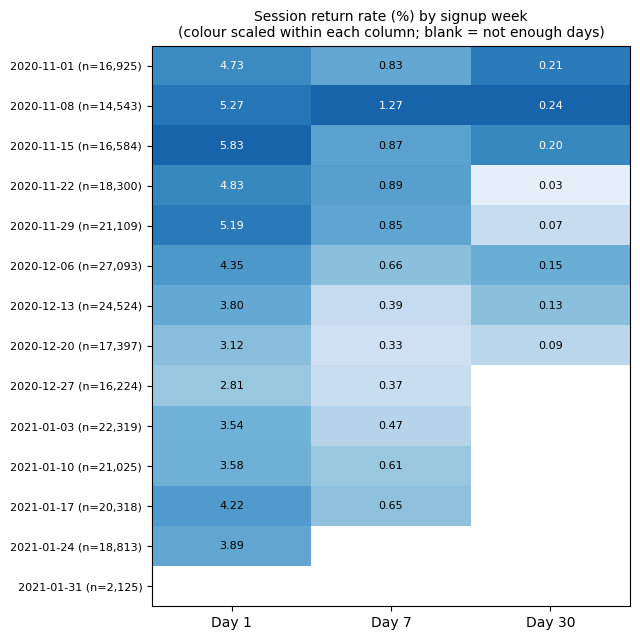

             users    D1    D7   D30
cohort_week                         
2020-11-01   16925  4.73  0.83  0.21
2020-11-08   14543  5.27  1.27  0.24
2020-11-15   16584  5.83  0.87  0.20
2020-11-22   18300  4.83  0.89  0.03
2020-11-29   21109  5.19  0.85  0.07
2020-12-06   27093  4.35  0.66  0.15
2020-12-13   24524  3.80  0.39  0.13
2020-12-20   17397  3.12  0.33  0.09
2020-12-27   16224  2.81  0.37   NaN
2021-01-03   22319  3.54  0.47   NaN
2021-01-10   21025  3.58  0.61   NaN
2021-01-17   20318  4.22  0.65   NaN
2021-01-24   18813  3.89   NaN   NaN
2021-01-31    2125   NaN   NaN   NaN


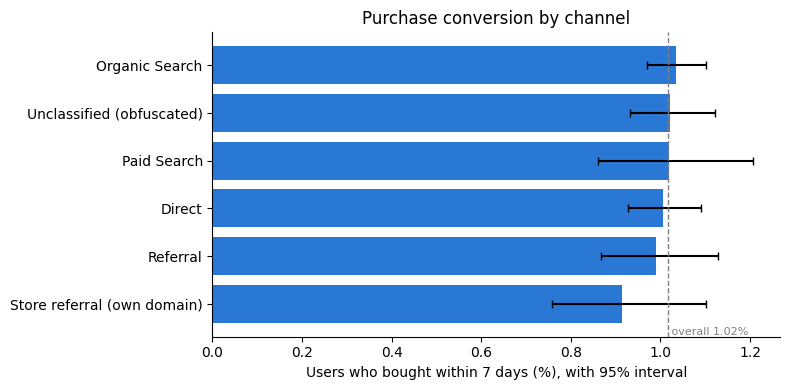

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from statsmodels.stats.proportion import proportion_confint
from google.colab import files

users['cohort_week'] = pd.to_datetime(users['cohort_week'])
f = users[users['eligible_d7_and_funnel']].copy()
f['bought_7d'] = f['orders_7d'] > 0

# Chart 1: reach-based funnel
stages = ['First visit', 'View item', 'Add to cart', 'Begin checkout', 'Purchase']
counts = [len(f), int(f['did_view_item_7d'].sum()), int(f['did_add_to_cart_7d'].sum()),
          int(f['did_begin_checkout_7d'].sum()), int(f['bought_7d'].sum())]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(stages[::-1], counts[::-1], color='#2a78d6')
for b, c in zip(bars, counts[::-1]):
    ax.text(b.get_width() + counts[0] * 0.01, b.get_y() + b.get_height() / 2,
            f"{c:,} ({100 * c / counts[0]:.2f}%)", va='center', fontsize=9)
ax.set_xlim(0, counts[0] * 1.35)
ax.set_xlabel('Users')
ax.set_title('Reach-based funnel: new users, 7 days from first visit (n = 238,636)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('funnel_reach_based.png', dpi=150)
plt.show()

# Chart 2: weekly cohort retention heatmap (a cohort is shown only if every user has had N days)
last = pd.Timestamp('2021-01-31')
rows = []
for wk, g in users.groupby('cohort_week'):
    row = {'cohort_week': wk.strftime('%Y-%m-%d'), 'users': len(g)}
    for n, col in [(1, 'ret_d1_session'), (7, 'ret_d7_session'), (30, 'ret_d30_session')]:
        row['D%d' % n] = 100 * g[col].astype(bool).mean() if wk + pd.Timedelta(days=6 + n) <= last else np.nan
    rows.append(row)
heat = pd.DataFrame(rows).set_index('cohort_week')
vals = heat[['D1', 'D7', 'D30']].values
norm = vals / np.nanmax(vals, axis=0)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.imshow(np.ma.masked_invalid(norm), cmap='Blues', aspect='auto', vmin=0, vmax=1.25)
ax.set_xticks(range(3))
ax.set_xticklabels(['Day 1', 'Day 7', 'Day 30'])
ax.set_yticks(range(len(heat)))
ax.set_yticklabels(['%s (n=%s)' % (i, format(u, ',')) for i, u in zip(heat.index, heat['users'])], fontsize=8)
for i in range(vals.shape[0]):
    for j in range(3):
        if not np.isnan(vals[i, j]):
            ax.text(j, i, '%.2f' % vals[i, j], ha='center', va='center', fontsize=8,
                    color='white' if norm[i, j] > 0.75 else 'black')
ax.set_title('Session return rate (%) by signup week\n(colour scaled within each column; blank = not enough days)', fontsize=10)
plt.tight_layout()
plt.savefig('retention_heatmap.png', dpi=150)
plt.show()
print(heat.round(2))

# Chart 3: purchase conversion by channel with 95% intervals
g = f[f['channel_group'] != 'Data deleted / other'].groupby('channel_group').agg(
    n=('user_id', 'count'), x=('bought_7d', 'sum'))
g['rate'] = 100 * g['x'] / g['n']
lo, hi = proportion_confint(g['x'], g['n'], method='wilson')
g['lo'] = 100 * lo
g['hi'] = 100 * hi
g = g.sort_values('rate')
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(g.index, g['rate'], xerr=[g['rate'] - g['lo'], g['hi'] - g['rate']], color='#2a78d6', capsize=3)
overall = 100 * f['bought_7d'].mean()
ax.axvline(overall, color='gray', linestyle='--', linewidth=1)
ax.text(overall, -0.65, ' overall %.2f%%' % overall, fontsize=8, color='gray')
ax.set_xlabel('Users who bought within 7 days (%), with 95% interval')
ax.set_title('Purchase conversion by channel')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('conversion_by_channel.png', dpi=150)
plt.show()

for name in ['funnel_reach_based.png', 'retention_heatmap.png', 'conversion_by_channel.png']:
    files.download(name)